<a href="https://colab.research.google.com/github/Nitin-Shukla-eng/Smart-Water-Monitoring-ESP32-S3/blob/main/Smart_Water_Purfication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd

# Load the public water-quality dataset
url = "https://huggingface.co/datasets/DarkNeuron-AI/water-potability-3k/resolve/main/water_potability.csv"

df = pd.read_csv(url)

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nPotability label counts:")
print(df["potability"].value_counts(dropna=False))


Dataset loaded successfully!
Dataset shape: (3276, 10)

First 5 rows:


,ph,hardness,solids,chloramines,sulfate,conductivity,organic_carbon,trihalomethanes,turbidity,potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0



Column names:
['ph', 'hardness', 'solids', 'chloramines', 'sulfate', 'conductivity', 'organic_carbon', 'trihalomethanes', 'turbidity', 'potability']

Missing values in each column:
ph                 491
hardness             0
solids               0
chloramines          0
sulfate            781
conductivity         0
organic_carbon       0
trihalomethanes    162
turbidity            0
potability           0
dtype: int64

Potability label counts:
potability
0    1998
1    1278
Name: count, dtype: int64


In [2]:

# Inspect every column and its data type
print("Dataset information:")
df.info()

print("\nMissing-value percentages:")
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

print("\nTarget distribution:")
print(df["potability"].value_counts(dropna=False))

print("\nSummary statistics:")
display(df.describe().T)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   hardness         3276 non-null   float64
 2   solids           3276 non-null   float64
 3   chloramines      3276 non-null   float64
 4   sulfate          2495 non-null   float64
 5   conductivity     3276 non-null   float64
 6   organic_carbon   3276 non-null   float64
 7   trihalomethanes  3114 non-null   float64
 8   turbidity        3276 non-null   float64
 9   potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB

Missing-value percentages:
sulfate            23.84
ph                 14.99
trihalomethanes     4.95
hardness            0.00
chloramines         0.00
solids              0.00
conductivity        0.00
organic_carbon      0.00
turbidity           0.00
potability     

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate input features and target
X = df.drop(columns=["potability"])
y = df["potability"]

# Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create preprocessing pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Learn missing-value replacements from training data only
X_train_clean = preprocessor.fit_transform(X_train)
X_test_clean = preprocessor.transform(X_test)

print("Training samples:", X_train_clean.shape[0])
print("Testing samples:", X_test_clean.shape[0])
print("Training features:", X_train_clean.shape[1])
print("Missing values after preprocessing:",
      __import__("numpy").isnan(X_train_clean).sum(),
      __import__("numpy").isnan(X_test_clean).sum())
print("\nTraining label distribution:")
print(y_train.value_counts())
print("\nTesting label distribution:")
print(y_test.value_counts())


Training samples: 2620
Testing samples: 656
Training features: 9
Missing values after preprocessing: 0 0

Training label distribution:
potability
0    1598
1    1022
Name: count, dtype: int64

Testing label distribution:
potability
0    400
1    256
Name: count, dtype: int64


Random Forest Results
Accuracy: 0.6707

Classification Report:
              precision    recall  f1-score   support

     Label 0       0.67      0.91      0.77       400
     Label 1       0.68      0.30      0.41       256

    accuracy                           0.67       656
   macro avg       0.67      0.60      0.59       656
weighted avg       0.67      0.67      0.63       656



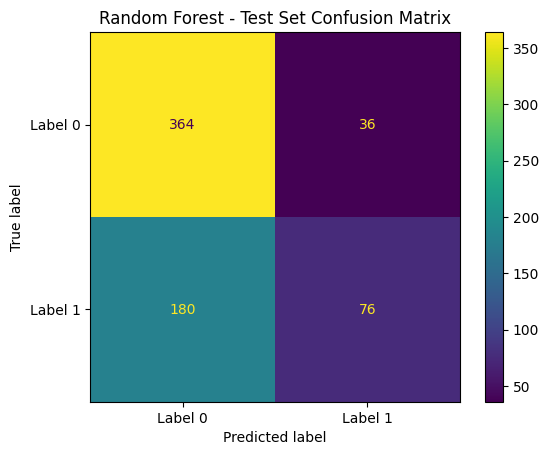


Feature Importance:


,importance
ph,0.129315
sulfate,0.126337
hardness,0.118498
chloramines,0.117692
solids,0.113492
conductivity,0.101356
turbidity,0.099512
organic_carbon,0.097155
trihalomethanes,0.096642


In [4]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Build the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train using only the training data
rf_model.fit(X_train_clean, y_train)

# Predict on unseen test samples
y_pred = rf_model.predict(X_test_clean)

# Evaluate performance
print("Random Forest Results")
print("=" * 40)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Label 0", "Label 1"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Label 0", "Label 1"]
)
disp.plot()
plt.title("Random Forest - Test Set Confusion Matrix")
plt.show()

# Display feature importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
display(importance.to_frame("importance"))


In [5]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

# Keep preprocessing inside the pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Try different model settings
param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 3],
    "model__class_weight": ["balanced", "balanced_subsample"]
}

# Search using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score for class 1:")
print(round(grid_search.best_score_, 4))

# Evaluate the selected model once on the held-out test set
best_model = grid_search.best_estimator_
tuned_pred = best_model.predict(X_test)

print("\nTuned model test accuracy:")
print(round(accuracy_score(y_test, tuned_pred), 4))

print("\nTuned model classification report:")
print(classification_report(
    y_test,
    tuned_pred,
    target_names=["Label 0", "Label 1"],
    zero_division=0
))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}

Best cross-validation F1-score for class 1:
0.489

Tuned model test accuracy:
0.6738

Tuned model classification report:
              precision    recall  f1-score   support

     Label 0       0.69      0.84      0.76       400
     Label 1       0.62      0.42      0.50       256

    accuracy                           0.67       656
   macro avg       0.66      0.63      0.63       656
weighted avg       0.66      0.67      0.66       656



In [6]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Reuse the original, unprocessed X_train and y_train.
# Imputation remains inside the pipeline.
accuracy_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

accuracy_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__min_samples_split": [2, 5],
    "model__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

accuracy_search = GridSearchCV(
    accuracy_pipeline,
    accuracy_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

accuracy_search.fit(X_train, y_train)

print("Best parameters:")
print(accuracy_search.best_params_)

print("\nBest cross-validation accuracy:")
print(round(accuracy_search.best_score_, 4))

# Evaluate the selected model on the held-out test set
accuracy_model = accuracy_search.best_estimator_
accuracy_pred = accuracy_model.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("\nHeld-out test accuracy:")
print(round(accuracy_score(y_test, accuracy_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    accuracy_pred,
    target_names=["Label 0", "Label 1"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, accuracy_pred))


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 400}

Best cross-validation accuracy:
0.6813

Held-out test accuracy:
0.6723

Classification report:
              precision    recall  f1-score   support

     Label 0       0.68      0.88      0.77       400
     Label 1       0.65      0.34      0.45       256

    accuracy                           0.67       656
   macro avg       0.66      0.61      0.61       656
weighted avg       0.67      0.67      0.64       656


Confusion matrix:
[[353  47]
 [168  88]]


In [7]:

from sklearn.base import clone
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier
)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=20,
        min_samples_leaf=2,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=15,
        random_state=42
    ),
    "SVM (RBF)": SVC(C=1.0, kernel="rbf"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator)
    ])

    # Estimate generalization on training data only
    cv_scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=cv, scoring="accuracy", n_jobs=-1
    )

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "CV Accuracy Mean": cv_scores.mean(),
        "CV Accuracy Std": cv_scores.std(),
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test F1 Label 1": f1_score(
            y_test, predictions, pos_label=1
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "CV Accuracy Mean", ascending=False
)

display(results_df.round(4))


,Model,CV Accuracy Mean,CV Accuracy Std,Test Accuracy,Test F1 Label 1
0,Random Forest,0.6813,0.0160,0.6723,0.4501
1,Extra Trees,0.6802,0.0171,0.6616,0.3729
2,HistGradientBoosting,0.6519,0.0161,0.6540,0.4423
3,SVM (RBF),0.6092,0.0014,0.6098,0.0000
4,Logistic Regression,0.4943,0.0251,0.5503,0.4974


Target proportions:
potability
0    0.61
1    0.39
Name: proportion, dtype: float64


potability,0,1
ph,7.085378,7.073783
hardness,196.733292,195.800744
solids,21777.490788,22383.991018
chloramines,7.092175,7.169338
sulfate,334.564290,332.566990
conductivity,426.730454,425.383800
organic_carbon,14.364335,14.160893
trihalomethanes,66.303555,66.539684
turbidity,3.965800,3.968328



Feature correlations with potability:


,correlation
organic_carbon,-0.030001
sulfate,-0.023577
hardness,-0.013837
conductivity,-0.008128
ph,-0.003556
turbidity,0.001581
trihalomethanes,0.007130
chloramines,0.023779
solids,0.033743


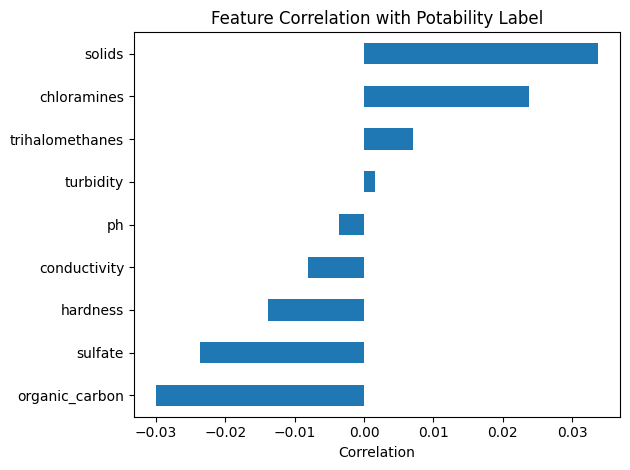

In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Examine target balance
print("Target proportions:")
print(df["potability"].value_counts(normalize=True).round(3))

# Compare feature distributions between the two labels
display(df.groupby("potability").mean(numeric_only=True).T)

# Correlation between numeric features and the target
correlations = (
    df.corr(numeric_only=True)["potability"]
    .drop("potability")
    .sort_values()
)

print("\nFeature correlations with potability:")
display(correlations.to_frame("correlation"))

correlations.plot(kind="barh")
plt.title("Feature Correlation with Potability Label")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()


In [9]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor
)
from sklearn.metrics import make_scorer, f1_score

X = df.drop(columns=["potability"])
y = df["potability"].astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=20,
        min_samples_leaf=2,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", model)
    ])

    scores = cross_validate(
        pipe,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_positive": make_scorer(f1_score, pos_label=1),
            "balanced_accuracy": "balanced_accuracy"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean CV accuracy": scores["test_accuracy"].mean(),
        "Mean CV F1 (class 1)": scores["test_f1_positive"].mean(),
        "Mean CV balanced accuracy": scores["test_balanced_accuracy"].mean()
    })

results_df = pd.DataFrame(results).sort_values(
    "Mean CV accuracy", ascending=False
)
display(results_df.round(3))

,Model,Mean CV accuracy,Mean CV F1 (class 1),Mean CV balanced accuracy
0,Random Forest,0.675,0.471,0.620
1,Extra Trees,0.672,0.474,0.620
2,Histogram Gradient Boosting,0.655,0.461,0.605
